# Lab 5: Random Forest Classification (Hyperparameter Tuning)

### Problem Statement:
Create Random Forests for classification on a sample dataset. Try different tree heights and different numbers of tree instances. Compare the results for Precision, Recall, and Accuracy, and draw a graph of the same.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.preprocessing import LabelEncoder

In [16]:
df = pd.read_csv("/content/loan_approval_dataset.csv")
df.columns = df.columns.str.strip()

In [17]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [18]:
le = LabelEncoder()
df['education'] = le.fit_transform(df['education'])
df['self_employed'] = le.fit_transform(df['self_employed'])
df['loan_status'] = le.fit_transform(df['loan_status'])

In [19]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,0,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,0
1,2,0,1,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,1
2,3,3,0,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,1
3,4,3,0,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,1
4,5,5,1,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,1


In [20]:
X = df.drop(['loan_id', 'loan_status'], axis=1)
y = df['loan_status']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Defining the hyperparameters to test:


In [22]:
n_estimators_list = [10, 50, 100]
max_depth_list = [5, 10, None]

results = []

In [23]:
for n in n_estimators_list:
    for d in max_depth_list:
        # Initialization
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=10)
        rf.fit(X_train, y_train)

        # Predictions
        y_pred = rf.predict(X_test)

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)

        depth_label = str(d) if d is not None else 'None (Max)'
        results.append({'Trees (n_estimators)': n, 'Depth (max_depth)': depth_label, 'Accuracy': acc,
                        'Precision': prec, 'Recall': rec
        })

In [24]:
results_df = pd.DataFrame(results)
print("Experiment Results:")
print(results_df.to_string(index=False))

results_melted = results_df.melt(
    id_vars=['Trees (n_estimators)', 'Depth (max_depth)'],
    value_vars=['Accuracy', 'Precision', 'Recall'],
    var_name='Metric',
    value_name='Score'
)

Experiment Results:
 Trees (n_estimators) Depth (max_depth)  Accuracy  Precision   Recall
                   10                 5  0.976581   0.968553 0.968553
                   10                10  0.973068   0.965300 0.962264
                   10        None (Max)  0.974239   0.977419 0.952830
                   50                 5  0.976581   0.959877 0.977987
                   50                10  0.980094   0.983923 0.962264
                   50        None (Max)  0.978923   0.980769 0.962264
                  100                 5  0.968384   0.950464 0.965409
                  100                10  0.975410   0.977492 0.955975
                  100        None (Max)  0.977752   0.977636 0.962264


Graph :

<Figure size 1400x800 with 0 Axes>

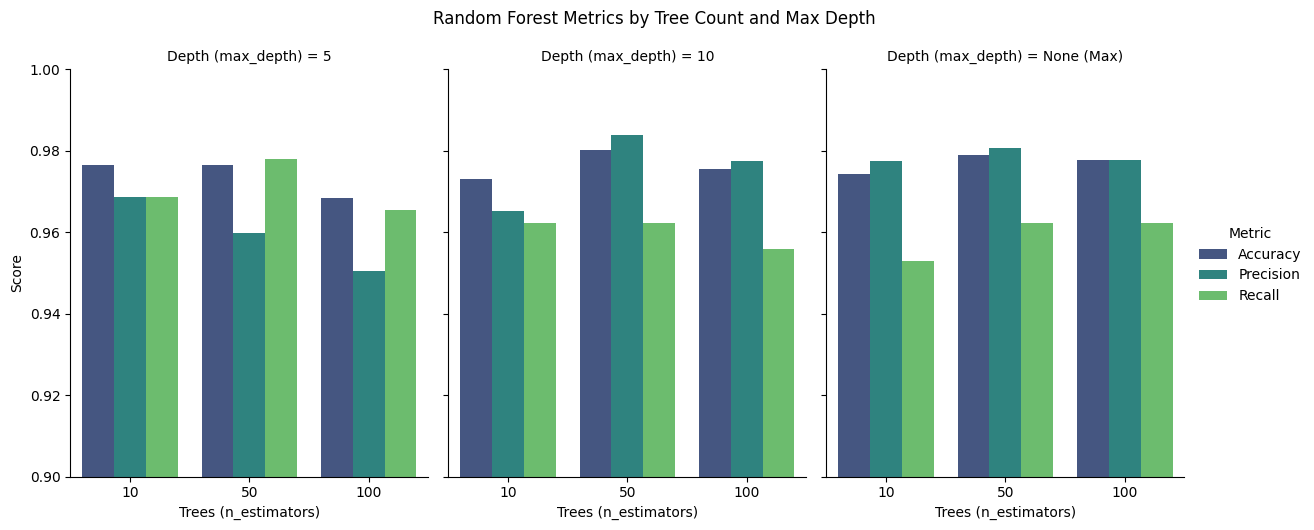

In [26]:
plt.figure(figsize=(14, 8))
g=sns.catplot(
    data=results_melted,
    x='Trees (n_estimators)',
    y='Score',
    hue='Metric',
    col='Depth (max_depth)',
    kind='bar',
    height=5,
    aspect=0.8,
    palette='viridis'
)
g.set(ylim=(0.90, 1.0))
plt.suptitle('Random Forest Metrics by Tree Count and Max Depth', y=1.05)
plt.show()